# Phase 2b — Hybrid Human + Pseudo-Label Training

**Low-Light Object Detection via Decoupled VLM Pseudo-Labelling**

Phase 2 established the endpoints: 100% human labels (Condition B) reached 0.621 mAP@[.5:.95],
0% human (Condition C @0.55) reached 0.420. Phase 2b fills in the curve between them.

A fraction of train images keep their **human** annotations; the rest use **VLM pseudo-labels**. Mixing
is at image level and the human subset is drawn **stratified by primary class** (seed 42), so every
class contributes proportionally. Two new runs — 10% and 25% human — turn two known endpoints into a
four-point annotation-budget curve.

## 1. Install and verify

Same pins as Phase 2 so the models are directly comparable.


In [1]:
!pip install -q "rfdetr[train,loggers]" supervision pycocotools

ok = True
try:
    import rfdetr
    print("rfdetr           :", getattr(rfdetr, "__version__", "unknown"))
except Exception as e:
    ok = False; print("rfdetr import FAILED:", e)
try:
    import pytorch_lightning
    print("pytorch_lightning:", pytorch_lightning.__version__, "(training deps OK)")
except ModuleNotFoundError:
    ok = False; print("pytorch_lightning MISSING — rerun this cell.")
import torch
print("torch            :", torch.__version__, "| CUDA:", torch.cuda.is_available())
if torch.cuda.is_available():
    print("GPU              :", torch.cuda.get_device_name(0))
assert ok, ("Training deps missing. If this fired right after install: "
            "Runtime -> Restart session, then run this cell FIRST.")
print("\nSection 1 OK.")


     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 79.9/79.9 kB 8.1 MB/s eta 0:00:00
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 49.7/49.7 kB 5.5 MB/s eta 0:00:00
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 50.5/50.5 kB 5.4 MB/s eta 0:00:00
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 44.0/44.0 kB 4.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 280.2/280.2 kB 24.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 588.1/588.1 kB 47.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 102.7/102.7 kB 12.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 852.4/852.4 kB 61.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 983.4/983.4 kB 71.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.4/1.4 MB 77.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 11.2/11.2 MB 141.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 3.6/3.6 MB 128.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━

## 2. Configuration

`human_fractions` defines the mix points. `pseudo_threshold` is fixed at 0.55 — the Phase 2 winner —
so the only variable across runs is how much human annotation is present.


In [2]:
import os
from dataclasses import dataclass

RUN_TAG = "yoloworld_v8"

@dataclass
class P2bConfig:
    drive_root: str = "/content/drive/MyDrive/ExDark_dataset"
    p1_manifest: str = (f"/content/drive/MyDrive/ExDark_dataset/phase1_outputs_{RUN_TAG}"
                        "/phase1_manifest.json")
    p2_handoff:  str = (f"/content/drive/MyDrive/ExDark_dataset/phase2_results_{RUN_TAG}"
                        "/phase2_handoff.json")

    work_root:   str = "/content/phase2b_datasets"
    p2_work:     str = "/content/phase2_datasets"      # reuse Phase 2's unzipped A/B if present
    ckpt_root:   str = f"/content/drive/MyDrive/ExDark_dataset/phase2b_checkpoints_{RUN_TAG}"
    results_dir: str = f"/content/drive/MyDrive/ExDark_dataset/phase2b_results_{RUN_TAG}"

    # ── the experiment ──
    human_fractions: tuple = (0.10, 0.25)   # new runs; 0.0 (=C) and 1.0 (=B) come from Phase 2
    pseudo_threshold: float = 0.55          # Phase 2 winner, held fixed
    stratify_seed: int = 42
    drop_empty_pseudo: bool = True          # pseudo images with no labels are dropped
    keep_empty_human: bool = True           # human images with no boxes are TRUE negatives — keep

    # ── training (identical to Phase 2) ──
    epochs: int = 25
    lr: float = 1e-4
    early_stopping: bool = True
    resolution: int = 0

    # ── evaluation ──
    eval_conf: float = 0.01
    max_detections: int = 100
    iou_match: float = 0.50

    # Phase 2 reference numbers (endpoints of the curve)
    phase2_results_json: str = (f"/content/drive/MyDrive/ExDark_dataset/phase2_results_{RUN_TAG}"
                                "/phase2_results.json")

CFG = P2bConfig()
for d in (CFG.work_root, CFG.ckpt_root, CFG.results_dir):
    os.makedirs(d, exist_ok=True)

def batch_config():
    name = torch.cuda.get_device_name(0).lower() if torch.cuda.is_available() else ""
    if "a100" in name or "h100" in name: return 16, 1
    if "l4" in name or "a10" in name or "v100" in name: return 8, 2
    return 4, 4
BATCH_SIZE, GRAD_ACCUM = batch_config()

RUN_NAMES = [f"H{int(f*100)}" for f in CFG.human_fractions]
print(f"Effective batch 16 -> batch_size={BATCH_SIZE}, grad_accum_steps={GRAD_ACCUM}")
print("Human fractions   :", CFG.human_fractions, "->", RUN_NAMES)
print("Pseudo threshold  :", CFG.pseudo_threshold, "(fixed)")
print("Results ->", CFG.results_dir)


Effective batch 16 -> batch_size=16, grad_accum_steps=1
Human fractions   : (0.1, 0.25) -> ['H10', 'H25']
Pseudo threshold  : 0.55 (fixed)
Results -> /content/drive/MyDrive/ExDark_dataset/phase2b_results_yoloworld_v8


## 3. Mount Drive & load Phase 1 / Phase 2 handoffs

Phase 1's manifest locates the pseudo-label bank and enhanced pool; Phase 2's results supply the
0% and 100% endpoints for the curve.


In [3]:
import json, glob, time
from google.colab import drive

def robust_mount(mountpoint="/content/drive", tries=3):
    for i in range(tries):
        try:
            drive.mount(mountpoint, force_remount=True); return
        except ValueError as e:
            print(f"[mount] attempt {i+1} failed: {e}")
            os.system(f"fusermount -u {mountpoint} 2>/dev/null")
            os.system(f"rm -rf {mountpoint}")
            time.sleep(3)
    drive.mount(mountpoint)

robust_mount()

def _load(path, label, required=True):
    if os.path.isfile(path):
        print(f"[{label}] loaded from {path}")
        return json.load(open(path))
    hits = sorted(glob.glob(os.path.join(CFG.drive_root, "**", os.path.basename(path)),
                            recursive=True))
    if hits:
        print(f"[{label}] loaded from {hits[0]}")
        return json.load(open(hits[0]))
    if required:
        raise FileNotFoundError(f"{label}: {os.path.basename(path)} not found.")
    print(f"[{label}] not found — continuing without it.")
    return None

M  = _load(CFG.p1_manifest, "phase1")
P2 = _load(CFG.phase2_results_json, "phase2", required=False)

CLASSES = M["classes"]
print("\nClasses          :", CLASSES)
print("Pseudo-label bank:", M["pseudo_label_bank"])
print("Enhanced pool    :", M["enhanced_pool_dir"])

# endpoints for the curve
ENDPOINTS = {}
if P2:
    for tag, key in [("B", 1.0), ("C@0.55", 0.0)]:
        r = (P2.get("results", {}).get(tag) or {}).get("metrics")
        if r:
            ENDPOINTS[key] = {"run": tag, "mAP": r.get("mAP"), "mAP50": r.get("mAP50")}
    print("\nPhase 2 endpoints:")
    for k, v in sorted(ENDPOINTS.items()):
        print(f"  {int(k*100):>3}% human ({v['run']:<7}) mAP={v['mAP']}  mAP@0.5={v['mAP50']}")
else:
    print("\n[warn] Phase 2 results not found — the curve will show only the new runs.")


[mount] attempt 1 failed: Mountpoint must not already contain files
Mounted at /content/drive
[phase1] loaded from /content/drive/MyDrive/ExDark_dataset/phase1_outputs_yoloworld_v8/phase1_manifest.json
[phase2] loaded from /content/drive/MyDrive/ExDark_dataset/phase2_results_yoloworld_v8/phase2_results.json

Classes          : ['Bicycle', 'Boat', 'Bottle', 'Bus', 'Car', 'Cat', 'Chair', 'Cup', 'Dog', 'Motorbike', 'People', 'Table']
Pseudo-label bank: /content/drive/MyDrive/ExDark_dataset/phase1_outputs_yoloworld_v8/pseudo_label_bank
Enhanced pool    : /content/drive/MyDrive/ExDark_dataset/ExDark_enhanced

Phase 2 endpoints:
    0% human (C@0.55 ) mAP=0.4203  mAP@0.5=0.7581
  100% human (B      ) mAP=0.6208  mAP@0.5=0.8829


## 4. Source datasets

`B_enh_human` supplies enhanced images plus human train annotations and the shared val/test splits;
the bank supplies pseudo-labels at 0.55. Both are reused from Phase 2's working directory when present.


In [4]:
import zipfile, shutil

def get_dataset(name, manifest, cfg):
    for root in (cfg.p2_work, cfg.work_root):
        d = os.path.join(root, name)
        if os.path.isfile(os.path.join(d, "train", "_annotations.coco.json")):
            print(f"[data] {name}: reusing {d}"); return d
    zpath = (manifest.get("persisted_zips", {}) or {}).get(name) or \
            os.path.join(manifest["dataset_zip_dir"], name + ".zip")
    if not os.path.isfile(zpath):
        raise FileNotFoundError(f"{name}: zip not found ({zpath})")
    dest = os.path.join(cfg.work_root, name)
    print(f"[data] unzipping {name} ..."); t = time.time()
    os.makedirs(dest, exist_ok=True)
    with zipfile.ZipFile(zpath) as z: z.extractall(dest)
    print(f"[data]   done in {time.time()-t:.0f}s")
    return dest

B_DIR = get_dataset("B_enh_human", M, CFG)

HUMAN_TRAIN = json.load(open(os.path.join(B_DIR, "train", "_annotations.coco.json")))
ttag = int(round(CFG.pseudo_threshold * 100))
BANK = os.path.join(M["pseudo_label_bank"], f"train_enhanced_vlm_t{ttag}.coco.json")
if not os.path.isfile(BANK):
    raise FileNotFoundError(f"bank JSON missing: {BANK}")
PSEUDO_TRAIN = json.load(open(BANK))

print(f"\nHuman train : {len(HUMAN_TRAIN['images'])} images, {len(HUMAN_TRAIN['annotations'])} boxes")
print(f"Pseudo train: {len(PSEUDO_TRAIN['images'])} images, {len(PSEUDO_TRAIN['annotations'])} boxes "
      f"(threshold {CFG.pseudo_threshold})")


[data] unzipping B_enh_human ...
[data]   done in 178s

Human train : 5886 images, 19105 boxes
Pseudo train: 5886 images, 13366 boxes (threshold 0.55)


## 5. Stratified human/pseudo assignment

The human subset is drawn per class so each of the 12 primary classes contributes the same fraction of
its images — the same stratification scheme Phase 1 used for train/val/test. Class is recovered from the
`<Class>__<stem>` filename convention the datasets were materialised with.

Every train image appears exactly once, labelled from one source or the other. Human images keep their
empties (a true negative); pseudo images with no labels are dropped, matching Phase 2's default.


In [5]:
import random
from collections import Counter, defaultdict

def primary_class_of(file_name):
    """Datasets were materialised as '<Class>__<stem><ext>'."""
    return file_name.split("__", 1)[0] if "__" in file_name else "UNKNOWN"

def stratified_human_ids(coco, fraction, seed):
    """Pick a per-class fraction of image ids for human labelling."""
    by_cls = defaultdict(list)
    for im in coco["images"]:
        by_cls[primary_class_of(im["file_name"])].append(im["id"])
    rng = random.Random(seed)
    chosen = set()
    per_cls = {}
    for cls, ids in by_cls.items():
        ids = sorted(ids); rng.shuffle(ids)
        k = int(round(len(ids) * fraction))
        chosen.update(ids[:k]); per_cls[cls] = (k, len(ids))
    return chosen, per_cls

def build_hybrid(fraction, human_coco, pseudo_coco, cfg):
    """Train COCO where a stratified fraction of images use human labels, the rest pseudo-labels."""
    human_by_id = {im["id"]: im for im in human_coco["images"]}
    human_anns  = defaultdict(list)
    for a in human_coco["annotations"]: human_anns[a["image_id"]].append(a)
    pseudo_anns = defaultdict(list)
    for a in pseudo_coco["annotations"]: pseudo_anns[a["image_id"]].append(a)
    # bank and B share image ids (both derive from the Phase 1 train manifest); verify
    pseudo_ids = {im["id"] for im in pseudo_coco["images"]}
    assert pseudo_ids <= set(human_by_id), \
        "pseudo image ids are not a subset of B's — the two COCO files are misaligned."

    human_ids, per_cls = stratified_human_ids(human_coco, fraction, cfg.stratify_seed)

    images, annotations, aid = [], [], 1
    n_h = n_p = n_drop = 0
    for im in human_coco["images"]:
        iid = im["id"]
        if iid in human_ids:
            anns, src = human_anns.get(iid, []), "human"
            if not anns and not cfg.keep_empty_human:
                n_drop += 1; continue
            n_h += 1
        else:
            anns, src = pseudo_anns.get(iid, []), "pseudo"
            if not anns and cfg.drop_empty_pseudo:
                n_drop += 1; continue
            n_p += 1
        rec = dict(im); rec["label_source"] = src
        images.append(rec)
        for a in anns:
            b = dict(a); b["id"] = aid; b["label_source"] = src
            annotations.append(b); aid += 1
    coco = {"images": images, "annotations": annotations, "categories": human_coco["categories"]}
    stats = {"fraction": fraction, "human_imgs": n_h, "pseudo_imgs": n_p, "dropped": n_drop,
             "total_imgs": len(images), "total_boxes": len(annotations),
             "human_boxes": sum(1 for a in annotations if a["label_source"] == "human"),
             "pseudo_boxes": sum(1 for a in annotations if a["label_source"] == "pseudo"),
             "per_class_human": per_cls}
    return coco, stats

HYBRIDS, HSTATS = {}, {}
for f in CFG.human_fractions:
    name = f"H{int(f*100)}"
    HYBRIDS[name], HSTATS[name] = build_hybrid(f, HUMAN_TRAIN, PSEUDO_TRAIN, CFG)
    s = HSTATS[name]
    print(f"[hybrid] {name}: {s['human_imgs']} human + {s['pseudo_imgs']} pseudo images "
          f"({s['dropped']} dropped) | {s['human_boxes']} human + {s['pseudo_boxes']} pseudo boxes")

import pandas as pd
print("\nPer-class human image counts (stratification check):")
_rows = {n: {c: v[0] for c, v in s["per_class_human"].items()} for n, s in HSTATS.items()}
_tot  = {c: v[1] for c, v in HSTATS[RUN_NAMES[0]]["per_class_human"].items()}
STRAT = pd.DataFrame(_rows).assign(total_in_class=pd.Series(_tot))
for n in RUN_NAMES:
    STRAT[f"{n}_pct"] = (100 * STRAT[n] / STRAT["total_in_class"]).round(1)
display(STRAT)


[hybrid] H10: 589 human + 4618 pseudo images (679 dropped) | 1865 human + 12069 pseudo boxes
[hybrid] H25: 1472 human + 3852 pseudo images (562 dropped) | 4700 human + 10095 pseudo boxes

Per-class human image counts (stratification check):


,H10,H25,total_in_class,H10_pct,H25_pct
Bicycle,52,130,521,10.0,25.0
Boat,54,136,543,9.9,25.0
Bottle,44,109,437,10.1,24.9
Bus,42,105,421,10.0,24.9
Car,51,128,510,10.0,25.1
Cat,59,147,588,10.0,25.0
Chair,52,130,518,10.0,25.1
Cup,42,104,415,10.1,25.1
Dog,64,160,640,10.0,25.0
Motorbike,40,100,402,10.0,24.9


### 5.1 Materialise the hybrid datasets

Each run gets its own folder: the hybrid train annotations plus the images they reference, with val/test
copied unchanged from B so every run in Phases 2 and 2b is scored on exactly the same ground truth.


In [6]:
def materialize_hybrid(name, coco, B_dir, cfg):
    dest = os.path.join(cfg.work_root, name)
    if os.path.isfile(os.path.join(dest, "train", "_annotations.coco.json")):
        print(f"[data] {name}: already built"); return dest
    for split in ["valid", "test"]:
        s, d = os.path.join(B_dir, split), os.path.join(dest, split)
        if os.path.isdir(s) and not os.path.isdir(d): shutil.copytree(s, d)
    tr = os.path.join(dest, "train"); os.makedirs(tr, exist_ok=True)
    src_tr = os.path.join(B_dir, "train")
    missing = 0
    for im in coco["images"]:
        s, d = os.path.join(src_tr, im["file_name"]), os.path.join(tr, im["file_name"])
        if os.path.isfile(s):
            if not os.path.exists(d): shutil.copy2(s, d)
        else:
            missing += 1
    json.dump(coco, open(os.path.join(tr, "_annotations.coco.json"), "w"))
    print(f"[data] {name}: train {len(coco['images'])} imgs / {len(coco['annotations'])} boxes"
          + (f" | {missing} missing" if missing else ""))
    return dest

DATASETS = {n: materialize_hybrid(n, HYBRIDS[n], B_DIR, CFG) for n in RUN_NAMES}

def normalize_coco_for_rfdetr(dataset_dir, classes):
    cats = [{"id": 0, "name": "exdark", "supercategory": "none"}] + \
           [{"id": i + 1, "name": c, "supercategory": "exdark"} for i, c in enumerate(classes)]
    name_to_id = {c: i + 1 for i, c in enumerate(classes)}
    for split in ["train", "valid", "test"]:
        jp = os.path.join(dataset_dir, split, "_annotations.coco.json")
        if not os.path.isfile(jp): continue
        coco = json.load(open(jp))
        if any(a["category_id"] not in name_to_id.values() for a in coco.get("annotations", [])):
            old = {c["id"]: c["name"] for c in coco.get("categories", [])}
            for a in coco["annotations"]:
                nm = old.get(a["category_id"])
                if nm in name_to_id: a["category_id"] = name_to_id[nm]
        coco["categories"] = cats
        json.dump(coco, open(jp, "w"))

for d in DATASETS.values():
    normalize_coco_for_rfdetr(d, CLASSES)

def dataset_stats(d):
    out = {}
    for split in ["train", "valid", "test"]:
        jp = os.path.join(d, split, "_annotations.coco.json")
        if os.path.isfile(jp):
            c = json.load(open(jp))
            out[f"{split}_imgs"] = len(c["images"]); out[f"{split}_boxes"] = len(c["annotations"])
    return out

DS_STATS = pd.DataFrame({t: dataset_stats(d) for t, d in DATASETS.items()}).T
print("\nVerification:"); display(DS_STATS)
_ref = DS_STATS.iloc[0]
for t in DS_STATS.index:
    for col in ["valid_imgs", "valid_boxes", "test_imgs", "test_boxes"]:
        if DS_STATS.loc[t, col] != _ref[col]:
            print(f"[WARN] {t}.{col} differs — mAP will not be comparable.")
print("[check] val/test consistency verified.")


[data] H10: train 5207 imgs / 13934 boxes
[data] H25: train 5324 imgs / 14795 boxes

Verification:


,train_imgs,train_boxes,valid_imgs,valid_boxes,test_imgs,test_boxes
H10,5207,13934,729,2387,748,2218
H25,5324,14795,729,2387,748,2218


[check] val/test consistency verified.


## 6. Train

Same hyper-parameters as Phase 2, so H10 and H25 sit on the same axis as B and C.


In [7]:
from rfdetr import RFDETRSmall

BEST_NAMES   = ["checkpoint_best_ema.pth", "checkpoint_best_total.pth", "checkpoint_best_regular.pth"]
RESUME_NAMES = ["last.ckpt", "checkpoint.pth", "checkpoint_best_total.pth",
                "checkpoint_best_ema.pth", "checkpoint_best_regular.pth"]

def _first_existing(out_dir, names):
    for n in names:
        p = os.path.join(out_dir, n)
        if os.path.isfile(p): return p
    hits = sorted(glob.glob(os.path.join(out_dir, "checkpoint_best*.pth")))
    return hits[0] if hits else None

def train_run(tag, dataset_dir, cfg):
    out_dir = os.path.join(cfg.ckpt_root, tag); os.makedirs(out_dir, exist_ok=True)
    if os.path.isfile(os.path.join(out_dir, ".done")):
        print(f"[train] {tag}: complete — skipping.")
        return out_dir, _first_existing(out_dir, BEST_NAMES)
    kwargs = dict(dataset_dir=dataset_dir, epochs=cfg.epochs, batch_size=BATCH_SIZE,
                  grad_accum_steps=GRAD_ACCUM, lr=cfg.lr, output_dir=out_dir,
                  early_stopping=cfg.early_stopping, tensorboard=True)
    if cfg.resolution: kwargs["resolution"] = cfg.resolution
    resume = _first_existing(out_dir, RESUME_NAMES); t = time.time()
    try:
        if resume:
            print(f"[train] {tag}: resuming from {os.path.basename(resume)}")
            RFDETRSmall().train(resume=resume, **kwargs)
        else:
            print(f"[train] {tag}: fresh ({cfg.epochs} epochs)")
            RFDETRSmall().train(**kwargs)
    except Exception as e:
        if resume:
            print(f"[train] {tag}: resume failed ({type(e).__name__}); restarting fresh.")
            RFDETRSmall().train(**kwargs)
        else:
            raise
    open(os.path.join(out_dir, ".done"), "w").write(str(cfg.epochs))
    print(f"[train] {tag}: finished in {(time.time()-t)/60:.1f} min")
    return out_dir, _first_existing(out_dir, BEST_NAMES)

RUN_CKPTS = {}
for tag in RUN_NAMES:
    out_dir, best = train_run(tag, DATASETS[tag], CFG)
    RUN_CKPTS[tag] = {"out_dir": out_dir, "best": best, "dataset": DATASETS[tag]}

print("\nRun status:")
for tag, i in RUN_CKPTS.items():
    print(f"  {tag:<6} done={os.path.isfile(os.path.join(i['out_dir'], '.done'))}  "
          f"best={os.path.basename(i['best']) if i['best'] else None}")


[train] H10: fresh (25 epochs)
[2026-08-02 05:17:14] [INFO] rf-detr - Downloading pretrained weights for /root/.roboflow/models/rf-detr-small.pth


/root/.roboflow/models/rf-detr-small.pth:   0%|          | 0.00/368M [00:00<?, ?iB/s]

[2026-08-02 05:17:37] [INFO] rf-detr - MD5 validation successful for /root/.roboflow/models/rf-detr-small.pth


[2026-08-02 05:17:37] [WARNING] rf-detr - Using a different number of positional encodings than DINOv2, which means we're not loading DINOv2 backbone weights. This is not a problem if finetuning a pretrained RF-DETR model.
[2026-08-02 05:17:37] [WARNING] rf-detr - Using patch size 16 instead of 14, which means we're not loading DINOv2 backbone weights. This is not a problem if finetuning a pretrained RF-DETR model.


[2026-08-02 05:17:39] [INFO] rf-detr - File /root/.roboflow/models/rf-detr-small.pth already exists with correct MD5 hash.


...

[2026-08-02 06:27:55] [INFO] rf-detr - Best regular checkpoint saved to /content/drive/MyDrive/ExDark_dataset/phase2b_checkpoints_yoloworld_v8/H25/checkpoint_best_regular.pth (epoch 3, monitor=val/mAP_50_95, value=0.482422)
[2026-08-02 06:27:55] [INFO] rf-detr - Best EMA mAP improved to 0.4890 (epoch 3)


INFO:pytorch_lightning.callbacks.early_stopping:Metric __rfdetr_effective_map__ improved by 0.002 >= min_delta = 0.001. New best score: 0.491


[2026-08-02 06:31:04] [INFO] rf-detr - Best EMA mAP improved to 0.4908 (epoch 4)


INFO:pytorch_lightning.callbacks.early_stopping:Monitored metric __rfdetr_effective_map__ did not improve in the last 10 records. Best score: 0.491. Signaling Trainer to stop.


[2026-08-02 07:02:56] [INFO] rf-detr - Best total checkpoint saved from EMA (regular=0.4824, ema=0.4908)
[train] H25: finished in 48.2 min

Run status:
  H10    done=True  best=checkpoint_best_ema.pth
  H25    done=True  best=checkpoint_best_ema.pth


## 7. Plotting helpers

`mark_axis_break` draws a double-slash on any axis not starting at 0; `pad_for_break` shifts the data up
and right so the first tick clears it. Call `pad_for_break` after plotting, before `mark_axis_break`.


In [8]:
import matplotlib.pyplot as plt
import numpy as np
import seaborn as sns
sns.set_theme(style="whitegrid")

def mark_axis_break(ax, x=None, y=None, size=0.012, gap=0.010, pos=0.045, lw=1.2):
    xlim, ylim = ax.get_xlim(), ax.get_ylim()
    if x is None: x = xlim[0] > 1e-9
    if y is None: y = ylim[0] > 1e-9
    kw = dict(transform=ax.transAxes, color="black", clip_on=False,
              linewidth=lw, solid_capstyle="butt", zorder=10)
    if x:
        for off in (-gap / 2, gap / 2):
            ax.plot([pos + off - size, pos + off + size], [-size, size], **kw)
    if y:
        for off in (-gap / 2, gap / 2):
            ax.plot([-size, size], [pos + off - size, pos + off + size], **kw)
    return ax

def pad_for_break(ax, frac=0.10, x=True, y=True):
    if x:
        x0, x1 = ax.get_xlim(); ax.set_xlim(x0 - frac * (x1 - x0), x1)
    if y:
        y0, y1 = ax.get_ylim(); ax.set_ylim(y0 - frac * (y1 - y0), y1)
    return ax

def savefig(fig, name):
    os.makedirs(CFG.results_dir, exist_ok=True)
    fig.savefig(os.path.join(CFG.results_dir, name), dpi=130, bbox_inches="tight")


## 8. Convergence

If a hybrid run is still improving at the epoch limit while B has flattened, its point on the curve is a
lower bound rather than a converged result.


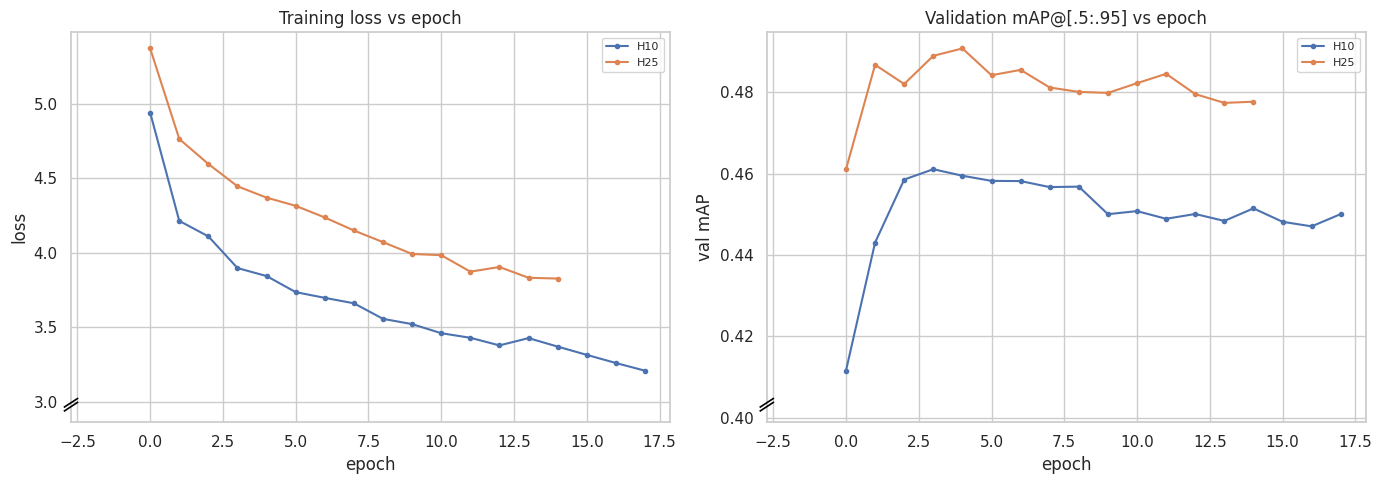

Final-epoch snapshot:
  H10    epoch=17  val_mAP=0.4501 (plateaued)
  H25    epoch=14  val_mAP=0.4777 (plateaued)


In [9]:
def load_metrics(out_dir):
    fp = os.path.join(out_dir, "metrics.csv")
    if not os.path.isfile(fp):
        hits = sorted(glob.glob(os.path.join(out_dir, "**", "metrics.csv"), recursive=True))
        fp = hits[0] if hits else None
    if not fp: return None
    df = pd.read_csv(fp)
    if "epoch" in df.columns:
        df = df.groupby("epoch", as_index=False).mean(numeric_only=True)
    return df

def _pick(cols, must, avoid=()):
    for c in cols:
        cl = c.lower()
        if all(m in cl for m in must) and not any(a in cl for a in avoid): return c
    return None

CURVES = {}
for tag, info in RUN_CKPTS.items():
    df = load_metrics(info["out_dir"])
    if df is None:
        print(f"[curves] {tag}: metrics.csv not found"); continue
    cols = list(df.columns)
    CURVES[tag] = {"df": df,
                   "loss": _pick(cols, ["train", "loss"]) or _pick(cols, ["loss"], avoid=["val"]),
                   "map":  _pick(cols, ["map", "50_95"]) or _pick(cols, ["map"], avoid=["50"])}

if CURVES:
    fig, axes = plt.subplots(1, 2, figsize=(14, 5))
    for tag, c in CURVES.items():
        df = c["df"]; x = df["epoch"] if "epoch" in df else range(len(df))
        if c["loss"]: axes[0].plot(x, df[c["loss"]], marker=".", label=tag)
        if c["map"]:  axes[1].plot(x, df[c["map"]],  marker=".", label=tag)
    axes[0].set_title("Training loss vs epoch"); axes[0].set_xlabel("epoch"); axes[0].set_ylabel("loss")
    axes[1].set_title("Validation mAP@[.5:.95] vs epoch"); axes[1].set_xlabel("epoch")
    axes[1].set_ylabel("val mAP")
    for ax in axes:
        ax.legend(fontsize=8); pad_for_break(ax); mark_axis_break(ax)
    plt.tight_layout(); savefig(fig, "convergence_curves.png"); plt.show()

    print("Final-epoch snapshot:")
    for tag, c in CURVES.items():
        df = c["df"]; last = df.iloc[-1]
        ep = int(last["epoch"]) if "epoch" in df else len(df)
        vmap = round(float(last[c["map"]]), 4) if c["map"] else None
        trend = ""
        if c["map"] and len(df) >= 4:
            trend = " (still improving)" if df[c["map"]].idxmax() >= len(df) - 3 else " (plateaued)"
        print(f"  {tag:<6} epoch={ep}  val_mAP={vmap}{trend}")


## 9. Evaluation

Identical protocol to Phase 2 — COCOeval with `maxDets=[1,10,100]` on the shared test split, plus a
per-detection dump with matched-GT IoU for the box-geometry check in §11.


In [10]:
from PIL import Image
from pycocotools.coco import COCO
from pycocotools.cocoeval import COCOeval
import contextlib, io as _io

def _load_model(best):
    try:    return RFDETRSmall.from_checkpoint(best)
    except Exception: return RFDETRSmall(pretrain_weights=best)

def _resolver(model, name_to_catid):
    names = getattr(model, "class_names", None)
    def r(cid, data):
        nm = None
        if isinstance(data, dict):
            a = data.get("class_name"); nm = a if isinstance(a, str) else None
        if nm is None and names is not None and 0 <= int(cid) < len(names): nm = names[int(cid)]
        if nm is not None:
            nm = str(nm)
            if nm in name_to_catid: return name_to_catid[nm]
            low = {k.lower(): v for k, v in name_to_catid.items()}
            if nm.lower() in low: return low[nm.lower()]
        if int(cid) in name_to_catid.values(): return int(cid)
        return int(cid) + 1
    return r

def _iou_xyxy(a, b):
    ix1, iy1 = max(a[0], b[0]), max(a[1], b[1])
    ix2, iy2 = min(a[2], b[2]), min(a[3], b[3])
    iw, ih = max(0.0, ix2 - ix1), max(0.0, iy2 - iy1)
    inter = iw * ih
    ua = max(0.0, a[2]-a[0]) * max(0.0, a[3]-a[1])
    ub = max(0.0, b[2]-b[0]) * max(0.0, b[3]-b[1])
    d = ua + ub - inter
    return inter / d if d > 0 else 0.0

def _area(b): return max(0.0, b[2]-b[0]) * max(0.0, b[3]-b[1])

def evaluate_run(tag, best, dataset_dir, cfg):
    test_dir = os.path.join(dataset_dir, "test")
    coco_gt = COCO(os.path.join(test_dir, "_annotations.coco.json"))
    cats = coco_gt.loadCats(coco_gt.getCatIds())
    name_to_catid = {c["name"]: c["id"] for c in cats if c["name"] != "exdark"}
    id_to_name = {c["id"]: c["name"] for c in cats}
    fname_to_id = {coco_gt.loadImgs(i)[0]["file_name"]: i for i in coco_gt.getImgIds()}

    model = _load_model(best); resolve = _resolver(model, name_to_catid)
    results, records = [], []
    for fn, img_id in fname_to_id.items():
        p = os.path.join(test_dir, fn)
        if not os.path.isfile(p): continue
        det = model.predict(Image.open(p).convert("RGB"), threshold=cfg.eval_conf)
        xyxy = getattr(det, "xyxy", None); conf = getattr(det, "confidence", None)
        cid  = getattr(det, "class_id", None); data = getattr(det, "data", {}) or {}
        n = 0 if xyxy is None else len(xyxy)
        order = np.argsort(-conf)[:cfg.max_detections] if (conf is not None and n) else range(n)
        gts = [{"id": a["id"], "cat": a["category_id"],
                "box": [a["bbox"][0], a["bbox"][1],
                        a["bbox"][0]+a["bbox"][2], a["bbox"][1]+a["bbox"][3]]}
               for a in coco_gt.loadAnns(coco_gt.getAnnIds(imgIds=img_id))]
        claimed = set()
        for k in order:
            x1, y1, x2, y2 = [float(v) for v in xyxy[k]]
            cname = data.get("class_name")[k] if isinstance(data, dict) and "class_name" in data else None
            catid = resolve(int(cid[k]), {"class_name": cname} if cname is not None else {})
            score = float(conf[k])
            results.append({"image_id": int(img_id), "category_id": int(catid),
                            "bbox": [x1, y1, x2-x1, y2-y1], "score": score})
            bi, bg = 0.0, None
            for gt in gts:
                if gt["cat"] != catid or gt["id"] in claimed: continue
                v = _iou_xyxy([x1, y1, x2, y2], gt["box"])
                if v > bi: bi, bg = v, gt["id"]
            tp = bi >= cfg.iou_match and bg is not None
            if tp: claimed.add(bg)
            records.append({"run": tag, "image_id": int(img_id), "file_name": fn,
                            "kind": "detection", "cls": id_to_name.get(catid, str(catid)),
                            "score": score, "best_iou": bi, "tp": bool(tp),
                            "gt_id": bg if tp else None,
                            "x1": x1, "y1": y1, "x2": x2, "y2": y2})
        for gt in gts:
            if gt["id"] not in claimed:
                records.append({"run": tag, "image_id": int(img_id), "file_name": fn,
                                "kind": "missed_gt", "cls": id_to_name.get(gt["cat"], str(gt["cat"])),
                                "score": np.nan, "best_iou": np.nan, "tp": False, "gt_id": gt["id"],
                                "x1": gt["box"][0], "y1": gt["box"][1],
                                "x2": gt["box"][2], "y2": gt["box"][3]})

    if not results:
        print(f"[eval] {tag}: no detections."); return None
    coco_dt = coco_gt.loadRes(results)
    ev = COCOeval(coco_gt, coco_dt, "bbox"); ev.params.maxDets = [1, 10, 100]
    with contextlib.redirect_stdout(_io.StringIO()):
        ev.evaluate(); ev.accumulate(); ev.summarize()
    prec = ev.eval["precision"]; idx50 = int(np.argmin(np.abs(ev.params.iouThrs - 0.5)))
    per, per50, ap_all, ap50_all = {}, {}, [], []
    for k, cid_ in enumerate(coco_gt.getCatIds()):
        nm = id_to_name.get(cid_, str(cid_))
        if nm == "exdark": continue
        pr = prec[:, :, k, 0, -1]; pr = pr[pr > -1]
        ap = float(pr.mean()) if pr.size else float("nan")
        pr5 = prec[idx50, :, k, 0, -1]; pr5 = pr5[pr5 > -1]
        ap5 = float(pr5.mean()) if pr5.size else float("nan")
        per[nm], per50[nm] = round(ap, 4), round(ap5, 4)
        if not np.isnan(ap): ap_all.append(ap)
        if not np.isnan(ap5): ap50_all.append(ap5)
    metrics = {"mAP": round(float(np.mean(ap_all)), 4) if ap_all else None,
               "mAP50": round(float(np.mean(ap50_all)), 4) if ap50_all else None,
               "per_class": per, "per_class_50": per50}
    df = pd.DataFrame(records)
    dump = os.path.join(CFG.results_dir, f"detections_{tag}.parquet")
    df.to_parquet(dump, index=False)
    print(f"[eval] {tag}: mAP@0.5={metrics['mAP50']}  mAP@[.5:.95]={metrics['mAP']}")
    return {"metrics": metrics, "records": df, "dump": dump}

EVAL = {}
for tag, info in RUN_CKPTS.items():
    if not info["best"]:
        print(f"[eval] {tag}: no checkpoint — skipping."); continue
    r = evaluate_run(tag, info["best"], info["dataset"], CFG)
    if r: EVAL[tag] = r


loading annotations into memory...
Done (t=0.01s)
creating index...
index created!


/usr/local/lib/python3.12/dist-packages/rfdetr/detr.py:545: FutureWarning: The `RFDETRBase` was deprecated since v1.7.0. It will be removed in v2.0.0.
  getattr(variant_obj, "__name__", symbol): variant_obj
/usr/local/lib/python3.12/dist-packages/rfdetr/detr.py:545: FutureWarning: The `RFDETRLargeDeprecated` was deprecated since v1.7.0. It will be removed in v2.0.0.
  getattr(variant_obj, "__name__", symbol): variant_obj
/usr/local/lib/python3.12/dist-packages/rfdetr/detr.py:545: FutureWarning: The `RFDETRSegPreview` was deprecated since v1.7.0. It will be removed in v2.0.0.
  getattr(variant_obj, "__name__", symbol): variant_obj
[2026-08-02 07:02:58] [WARNING] rf-detr - Using a different number of positional encodings than DINOv2, which means we're not loading DINOv2 backbone weights. This is not a problem if finetuning a pretrained RF-DETR model.
[2026-08-02 07:02:58] [WARNING] rf-detr - Using patch size 16 instead of 14, which means we're not loading DINOv2 backbone weights. This is

Loading and preparing results...
DONE (t=0.07s)
creating index...
index created!
[eval] H10: mAP@0.5=0.7993  mAP@[.5:.95]=0.4494
loading annotations into memory...
Done (t=0.01s)
creating index...
index created!


[2026-08-02 07:03:54] [WARNING] rf-detr - Using a different number of positional encodings than DINOv2, which means we're not loading DINOv2 backbone weights. This is not a problem if finetuning a pretrained RF-DETR model.
[2026-08-02 07:03:54] [WARNING] rf-detr - Using patch size 16 instead of 14, which means we're not loading DINOv2 backbone weights. This is not a problem if finetuning a pretrained RF-DETR model.
[2026-08-02 07:03:55] [WARNING] rf-detr - load_pretrain_weights: checkpoint lacks args.num_queries / args.group_detr; falling back to flat slice. With group_detr=13 this may scramble per-group query structure if the checkpoint was trained with group_detr > 1.
[2026-08-02 07:03:55] [WARNING] rf-detr - Model is not optimized for inference. Latency may be higher than expected. For full GPU throughput (e.g. ~8x on T4 via FP16 Tensor Cores), call model.inference(dtype=torch.float16).


Loading and preparing results...
DONE (t=0.51s)
creating index...
index created!
[eval] H25: mAP@0.5=0.8267  mAP@[.5:.95]=0.4794


## 10. The annotation-budget curve

Four points: 0% human (Phase 2's C@0.55), 10%, 25%, and 100% (Phase 2's B). The headline number is the
**recovery fraction** — how much of the C→B gap each mix closes:

`recovery = (mAP(H) − mAP(C)) / (mAP(B) − mAP(C))`

If 10% human labels recover far more than 10% of the gap, the return on annotation is steeply
front-loaded and that is the finding.


=== Annotation-budget curve ===


,human_pct,run,mAP,mAP50,source,recovery_%,gap_to_B,efficiency,human_imgs
0,0,C@0.55,0.4203,0.7581,phase2,0.0,0.2005,NaN,0
1,10,H10,0.4494,0.7993,phase2b,14.5,0.1714,1.45,589
2,25,H25,0.4794,0.8267,phase2b,29.5,0.1414,1.18,1472
3,100,B,0.6208,0.8829,phase2,100.0,0.0000,1.00,5207


10% human labels (589 images) recover 14.5% of the pseudo-to-human gap (1.45x return per point of annotation)
25% human labels (1472 images) recover 29.5% of the pseudo-to-human gap (1.18x return per point of annotation)


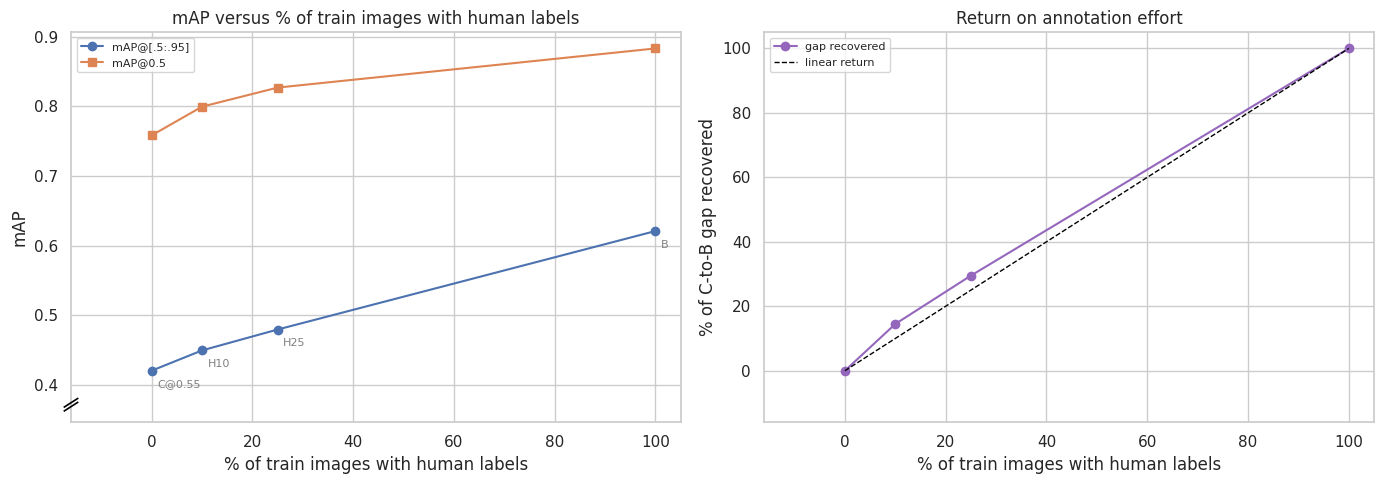

In [14]:
pts = []
if 0.0 in ENDPOINTS:
    pts.append({"human_pct": 0, "run": ENDPOINTS[0.0]["run"],
                "mAP": ENDPOINTS[0.0]["mAP"], "mAP50": ENDPOINTS[0.0]["mAP50"], "source": "phase2"})
for tag in RUN_NAMES:
    if tag in EVAL:
        m = EVAL[tag]["metrics"]
        pts.append({"human_pct": int(tag[1:]), "run": tag,
                    "mAP": m["mAP"], "mAP50": m["mAP50"], "source": "phase2b"})
if 1.0 in ENDPOINTS:
    pts.append({"human_pct": 100, "run": ENDPOINTS[1.0]["run"],
                "mAP": ENDPOINTS[1.0]["mAP"], "mAP50": ENDPOINTS[1.0]["mAP50"], "source": "phase2"})

CURVE = pd.DataFrame(pts).sort_values("human_pct").reset_index(drop=True)

lo = CURVE.loc[CURVE.human_pct == 0, "mAP"]
hi = CURVE.loc[CURVE.human_pct == 100, "mAP"]
if len(lo) and len(hi) and (hi.iloc[0] - lo.iloc[0]) != 0:
    lo_v, hi_v = float(lo.iloc[0]), float(hi.iloc[0])
    CURVE["recovery_%"] = (100 * (CURVE["mAP"] - lo_v) / (hi_v - lo_v)).round(1)
    CURVE["gap_to_B"]   = (hi_v - CURVE["mAP"]).round(4)
    CURVE["efficiency"] = (CURVE["recovery_%"] / CURVE["human_pct"].replace(0, np.nan)).round(2)

# human images actually used, for the annotation-cost axis
_used = {int(n[1:]): HSTATS[n]["human_imgs"] for n in RUN_NAMES if n in HSTATS}
CURVE["human_imgs"] = CURVE["human_pct"].map(
    lambda p: 0 if p == 0 else (_used.get(p) if p in _used else int(DS_STATS.iloc[0]["train_imgs"])))

print("=== Annotation-budget curve ===")
display(CURVE)

if "recovery_%" in CURVE:
    for _, r in CURVE.iterrows():
        if 0 < r.human_pct < 100:
            print(f"{int(r.human_pct)}% human labels ({int(r.human_imgs)} images) recover "
                  f"{r['recovery_%']}% of the pseudo-to-human gap "
                  f"({r.efficiency}x return per point of annotation)")

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
ax = axes[0]
ax.plot(CURVE.human_pct, CURVE.mAP, "-o", label="mAP@[.5:.95]")
ax.plot(CURVE.human_pct, CURVE.mAP50, "-s", label="mAP@0.5")
for _, r in CURVE.iterrows():
    ax.annotate(r.run, (r.human_pct, r.mAP), textcoords="offset points",
                xytext=(4, -12), fontsize=8, color="grey")
ax.set_xlabel("% of train images with human labels"); ax.set_ylabel("mAP")
ax.set_title("mAP versus % of train images with human labels"); ax.legend(fontsize=8)
pad_for_break(ax); mark_axis_break(ax)

ax = axes[1]
if "recovery_%" in CURVE:
    ax.plot(CURVE.human_pct, CURVE["recovery_%"], "-o", color="tab:purple", label="gap recovered")
    ax.plot([0, 100], [0, 100], ls="--", color="black", lw=1, label="linear return")
    ax.set_xlabel("% of train images with human labels")
    ax.set_ylabel("% of C-to-B gap recovered")
    ax.set_title("Return on annotation effort"); ax.legend(fontsize=8)
    pad_for_break(ax); mark_axis_break(ax)
plt.tight_layout(); savefig(fig, "annotation_budget_curve.png"); plt.show()


## 11. Per-class behaviour & box geometry

Two questions. First, do the classes Phase 2 found broken under pure pseudo-labelling — **Boat** and
**Table** — recover with a small human budget, and do they recover faster than the average class?

Second, does adding human labels pull box geometry back toward ExDark's convention? Phase 2 found C
drew boxes ~15% tighter than GT (32.7% of matched detections tighter, versus ~6% for B). If that share
falls as the human fraction rises, it confirms the tightness was learned from the teacher.


=== Per-class AP@[.5:.95] across the curve ===


,Bicycle,Boat,Bottle,Bus,Car,Cat,Chair,Cup,Dog,Motorbike,People,Table
0% (C),0.4429,0.2025,0.3193,0.6500,0.4817,0.4441,0.4242,0.3773,0.4164,0.5143,0.4354,0.3352
10% (H10),0.4475,0.2576,0.3407,0.6576,0.5075,0.4576,0.4369,0.4007,0.4510,0.5498,0.4517,0.4349
25% (H25),0.5024,0.2998,0.3560,0.6862,0.5303,0.4831,0.4856,0.4378,0.4544,0.5677,0.4706,0.4793
100% (B),0.5902,0.5234,0.6001,0.7962,0.6266,0.6230,0.5827,0.6117,0.6860,0.6615,0.5898,0.5585



=== Per-class gap recovery (higher = benefits most from human labels) ===


,AP_0%,AP_100%,AP_10%,recovery_10%,AP_25%,recovery_25%
Table,0.3352,0.5585,0.4349,44.6,0.4793,64.5
Bicycle,0.4429,0.5902,0.4475,3.1,0.5024,40.4
Chair,0.4242,0.5827,0.4369,8.0,0.4856,38.7
Motorbike,0.5143,0.6615,0.5498,24.1,0.5677,36.3
Car,0.4817,0.6266,0.5075,17.8,0.5303,33.5
Boat,0.2025,0.5234,0.2576,17.2,0.2998,30.3
Cup,0.3773,0.6117,0.4007,10.0,0.4378,25.8
Bus,0.6500,0.7962,0.6576,5.2,0.6862,24.8
People,0.4354,0.5898,0.4517,10.6,0.4706,22.8
Cat,0.4441,0.6230,0.4576,7.5,0.4831,21.8


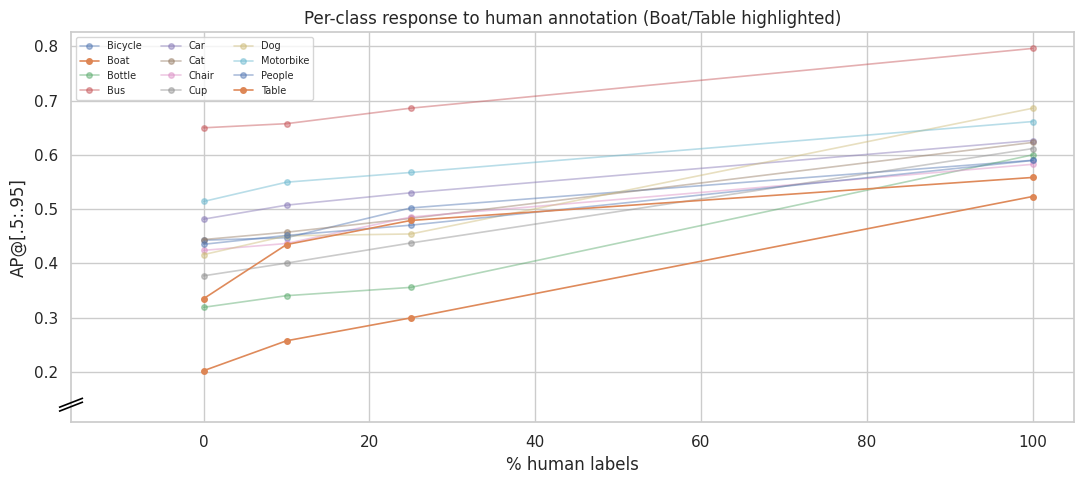

loading annotations into memory...
Done (t=0.01s)
creating index...
index created!
loading annotations into memory...
Done (t=0.01s)
creating index...
index created!

=== Box geometry vs ExDark annotation style ===


,matched,%tighter,%looser,median_area_ratio
H10,1352.0,32.3,3.0,1.148
H25,1364.0,27.9,2.5,1.138


In [12]:
# ── per-class AP across the curve ──
rows = {}
if 0.0 in ENDPOINTS and P2:
    r = (P2.get("results", {}).get(ENDPOINTS[0.0]["run"]) or {}).get("metrics") or {}
    if r.get("per_class"): rows["0% (C)"] = r["per_class"]
for tag in RUN_NAMES:
    if tag in EVAL: rows[f"{int(tag[1:])}% ({tag})"] = EVAL[tag]["metrics"]["per_class"]
if 1.0 in ENDPOINTS and P2:
    r = (P2.get("results", {}).get(ENDPOINTS[1.0]["run"]) or {}).get("metrics") or {}
    if r.get("per_class"): rows["100% (B)"] = r["per_class"]

PER_CLASS = pd.DataFrame(rows).T
print("=== Per-class AP@[.5:.95] across the curve ===")
display(PER_CLASS)

if len(PER_CLASS) >= 2:
    base, top = PER_CLASS.iloc[0], PER_CLASS.iloc[-1]
    REC = pd.DataFrame({"AP_0%": base, "AP_100%": top})
    for i in range(1, len(PER_CLASS) - 1):
        lbl = PER_CLASS.index[i]
        REC[f"AP_{lbl.split('%')[0]}%"] = PER_CLASS.iloc[i]
        REC[f"recovery_{lbl.split('%')[0]}%"] = (
            100 * (PER_CLASS.iloc[i] - base) / (top - base).replace(0, np.nan)).round(1)
    REC = REC.sort_values(REC.columns[-1], ascending=False)
    print("\n=== Per-class gap recovery (higher = benefits most from human labels) ===")
    display(REC)

    fig, ax = plt.subplots(figsize=(11, 5))
    for cls in PER_CLASS.columns:
        ax.plot([int(i.split("%")[0]) for i in PER_CLASS.index], PER_CLASS[cls],
                marker="o", ms=4, lw=1.2,
                label=cls, alpha=0.95 if cls in ("Boat", "Table") else 0.45)
    ax.set_xlabel("% human labels"); ax.set_ylabel("AP@[.5:.95]")
    ax.set_title("Per-class response to human annotation (Boat/Table highlighted)")
    ax.legend(fontsize=7, ncol=3)
    pad_for_break(ax); mark_axis_break(ax)
    plt.tight_layout(); savefig(fig, "per_class_curve.png"); plt.show()

# ── box geometry vs human fraction ──
TIGHTER_MARGIN, CONTAIN_MIN = 1.25, 0.85

def tightness(tag, dataset_dir):
    coco_gt = COCO(os.path.join(dataset_dir, "test", "_annotations.coco.json"))
    ann = {a["id"]: a for a in coco_gt.loadAnns(coco_gt.getAnnIds())}
    df = EVAL[tag]["records"]
    d = df[(df.kind == "detection") & df.tp & (df.score >= 0.50) & df.gt_id.notna()]
    n_t = n_l = 0; ratios = []
    for r in d.itertuples():
        a = ann.get(int(r.gt_id))
        if a is None: continue
        b = a["bbox"]; gb = [b[0], b[1], b[0]+b[2], b[1]+b[3]]; pb = [r.x1, r.y1, r.x2, r.y2]
        pa, ga = _area(pb), _area(gb)
        if pa <= 0 or ga <= 0: continue
        ix1, iy1 = max(pb[0], gb[0]), max(pb[1], gb[1])
        ix2, iy2 = min(pb[2], gb[2]), min(pb[3], gb[3])
        inter = max(0.0, ix2-ix1) * max(0.0, iy2-iy1)
        ratio = ga / pa; ratios.append(ratio)
        if ratio >= TIGHTER_MARGIN and inter / pa >= CONTAIN_MIN: n_t += 1
        elif (1/ratio) >= TIGHTER_MARGIN and inter / ga >= CONTAIN_MIN: n_l += 1
    n = len(ratios)
    return {"matched": n, "%tighter": round(100*n_t/n, 1) if n else None,
            "%looser": round(100*n_l/n, 1) if n else None,
            "median_area_ratio": round(float(np.median(ratios)), 3) if n else None}

TIGHT = pd.DataFrame({t: tightness(t, RUN_CKPTS[t]["dataset"]) for t in EVAL}).T
if P2 and P2.get("tightness_audit"):
    ref = pd.DataFrame(P2["tightness_audit"]).set_index("Run")
    for r in ["C@0.55", "B"]:
        if r in ref.index:
            TIGHT.loc[f"{r} (phase2)"] = {
                "matched": ref.loc[r, "matched_dets"], "%tighter": ref.loc[r, "%tighter"],
                "%looser": ref.loc[r, "%looser"], "median_area_ratio": ref.loc[r, "median_area_ratio"]}
print("\n=== Box geometry vs ExDark annotation style ===")
display(TIGHT)


## 12. Persist & interpret

Writes the curve, per-class recovery, geometry table and run metrics to
`phase2b_results_yoloworld_v8/`.


In [13]:
os.makedirs(CFG.results_dir, exist_ok=True)

PHASE2B = {
    "run_tag": RUN_TAG,
    "config": {"human_fractions": list(CFG.human_fractions),
               "pseudo_threshold": CFG.pseudo_threshold,
               "stratify_seed": CFG.stratify_seed,
               "stratified_by": "primary_class",
               "drop_empty_pseudo": CFG.drop_empty_pseudo,
               "keep_empty_human": CFG.keep_empty_human,
               "epochs": CFG.epochs, "lr": CFG.lr,
               "batch_size": BATCH_SIZE, "grad_accum_steps": GRAD_ACCUM},
    "classes": CLASSES,
    "hybrid_stats": {k: {kk: vv for kk, vv in v.items() if kk != "per_class_human"}
                     for k, v in HSTATS.items()},
    "results": {t: e["metrics"] for t, e in EVAL.items()},
    "curve": CURVE.to_dict("records"),
    "endpoints_from_phase2": ENDPOINTS,
    "checkpoints": {t: i["best"] for t, i in RUN_CKPTS.items()},
}
json.dump(PHASE2B, open(os.path.join(CFG.results_dir, "phase2b_results.json"), "w"),
          indent=2, default=str)

CURVE.to_csv(os.path.join(CFG.results_dir, "annotation_budget_curve.csv"), index=False)
PER_CLASS.to_csv(os.path.join(CFG.results_dir, "phase2b_per_class_ap.csv"))
TIGHT.to_csv(os.path.join(CFG.results_dir, "phase2b_box_geometry.csv"))
STRAT.to_csv(os.path.join(CFG.results_dir, "phase2b_stratification.csv"))
if "REC" in dir(): REC.to_csv(os.path.join(CFG.results_dir, "phase2b_per_class_recovery.csv"))

print("Saved to", CFG.results_dir)
for f in sorted(os.listdir(CFG.results_dir)): print("  -", f)
print("\n=== Curve ==="); display(CURVE)


Saved to /content/drive/MyDrive/ExDark_dataset/phase2b_results_yoloworld_v8
  - annotation_budget_curve.csv
  - annotation_budget_curve.png
  - convergence_curves.png
  - detections_H10.parquet
  - detections_H25.parquet
  - per_class_curve.png
  - phase2b_box_geometry.csv
  - phase2b_per_class_ap.csv
  - phase2b_per_class_recovery.csv
  - phase2b_results.json
  - phase2b_stratification.csv

=== Curve ===


,human_pct,run,mAP,mAP50,source,recovery_%,gap_to_B,efficiency,human_imgs
0,0,C@0.55,0.4203,0.7581,phase2,0.0,0.2005,NaN,0
1,10,H10,0.4494,0.7993,phase2b,14.5,0.1714,1.45,589
2,25,H25,0.4794,0.8267,phase2b,29.5,0.1414,1.18,1472
3,100,B,0.6208,0.8829,phase2,100.0,0.0000,1.00,5207
